# Figure 4: Behavioral Motif Encoding and Decoding

**Paper**: Parodi et al. (2026)

This notebook reproduces the motif analysis for Figure 4:
- **Panel A**: Motif decoding accuracy (logistic regression from neural population)
- **Panel B**: Electrode-level tuning and selectivity
- **Panel C**: Transition matrix between behavioral syllables
- **Panel D**: Peri-event time histogram (PETH) around motif transitions

**Behavioral syllables** are defined by an unsupervised motion segmentation pipeline (keypoint-MoSeq style) that identifies 10-12 recurring posture-movement patterns (e.g., Rest, Stand, Pace, Pivot, Inspect).

**Note**: This notebook runs with 10 permutations for speed (~4 min). Production uses 1000 permutations.

In [1]:
import sys, warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", message=".*lbfgs failed to converge.*")
warnings.filterwarnings("ignore", message=".*y_pred contains classes not in y_true.*")

REPO_ROOT = Path("..").resolve()
sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 14,
    'xtick.labelsize': 11, 'ytick.labelsize': 11, 'legend.fontsize': 11,
    'figure.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
})

SESSION_RENAME = {
    "hedy_0526": "M2_0526", "hedy_0605": "M2_0605",
    "hooke_0525": "M1_0525", "hooke_0609": "M1_0609", "hooke_0613": "M1_0613",
}
print("Setup complete.")

Setup complete.


## 4.1 Run Motif Analysis

Run the full Fig 4 pipeline: motif decoding, tuning, transition analysis, and PETH.

In [2]:
from freemat.single_fm.encoding.run_fig4 import Fig4Config, run_fig4_session
import tempfile

config = Fig4Config(
    bin_s=0.5,
    top_n=10,          # Top 10 motif classes
    n_perm=10,         # 10 permutations (production: 1000)
    debug=True,
)

with tempfile.TemporaryDirectory() as tmpdir:
    results = run_fig4_session(
        session_yaml=str(REPO_ROOT / "configs" / "session_M2_0526.yaml"),
        config=config,
        output_dir=tmpdir,
    )
    # Extract results
    decoding = results.get("decoding")
    tuning = results.get("tuning")
    transition_matrix = results.get("transition_matrix")
    peth = results.get("peth")
    fine_peth = results.get("fine_peth")

print(f"\nDecoding accuracy: {decoding['accuracy']:.1%} (chance: {decoding['chance']:.1%})")
print(f"Number of motif classes: {decoding['n_classes']}")
print(f"Transition matrix shape: {transition_matrix.shape}")
print(f"PETH shape: {peth.shape} (units × time bins)")

(Demo cell skipped during automated execution)


## 4.2 Panel A: Decoding Accuracy

Motif decoding accuracy from neural population activity using temporal cross-validation with 2s embargo.

In [3]:
# Panel A: Decoding accuracy bar chart
fig, ax = plt.subplots(figsize=(6, 5))

acc = decoding["accuracy"]
chance = decoding["chance"]
n_classes = decoding["n_classes"]

ax.bar(["Neural\nDecoding", "Chance"], [acc, chance],
       color=["#1976D2", "#BDBDBD"], edgecolor="black", linewidth=0.5, width=0.5)
ax.set_ylabel("Balanced Accuracy")
ax.set_title(f"Fig 4A: Motif Decoding — {n_classes} classes")
ax.set_ylim(0, max(acc, chance) * 1.3)

# Annotate
ax.text(0, acc + 0.01, f"{acc:.1%}", ha="center", fontsize=12, fontweight="bold")
ax.text(1, chance + 0.01, f"{chance:.1%}", ha="center", fontsize=12)

plt.tight_layout()
plt.show()

print(f"Decoding: {acc:.1%} vs chance {chance:.1%} ({acc/chance:.1f}× above chance)")

(Demo cell skipped during automated execution)


## 4.3 Panel C: Transition Matrix

Probability of transitioning between motifs. High diagonal = strong self-transition (behavioral persistence).

In [4]:
# Panel C: Transition matrix
fig, ax = plt.subplots(figsize=(8, 7))

im = ax.imshow(transition_matrix, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xlabel("Next Motif")
ax.set_ylabel("Current Motif")
ax.set_title("Fig 4C: Motif Transition Probabilities")

# Add text annotations
for i in range(transition_matrix.shape[0]):
    for j in range(transition_matrix.shape[1]):
        val = transition_matrix[i, j]
        if val > 0.01:
            color = "white" if val > 0.5 else "black"
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=8, color=color)

plt.colorbar(im, ax=ax, label="Transition Probability", shrink=0.8)

diag_mean = np.diag(transition_matrix).mean()
print(f"Mean self-transition probability: {diag_mean:.3f}")

plt.tight_layout()
plt.show()

(Demo cell skipped during automated execution)


---

## Part B: Publication Figure (Production Results)

![Fig 4: Pose Schematic](assets/fig4_pose_schematic.png)

Generate the Figure 4 composite using pre-computed production results (1000 permutations, all 5 sessions). Panels B/C (TGM) are placeholders — temporal generalization was not run in production.

In [5]:
# Load production data
import json
from freemat.single_fm.viz.pub_data import load_fig4, FIG4_SESSION_DIRS

fig4_data = load_fig4()

# Load TGM data (temporal generalization matrices)
tgm_data = {}
tgm_dir = REPO_ROOT / "results" / "fig4_tgm"
SESSION_RENAME = {"hedy_0526": "M2_0526", "hedy_0605": "M2_0605", "hooke_0525": "M1_0525", "hooke_0609": "M1_0609", "hooke_0613": "M1_0613"}
for old_name, new_name in SESSION_RENAME.items():
    tgm_path = tgm_dir / f"single_0{old_name.split('_')[1]}_{old_name.split('_')[0]}" / "fig4_tgm.npz"
    if not tgm_path.exists():
        # Try alternative naming
        for d in tgm_dir.iterdir():
            if d.is_dir() and old_name.split("_")[1] in d.name:
                alt = d / "fig4_tgm.npz"
                if alt.exists():
                    tgm_path = alt
                    break
    if tgm_path.exists():
        npz = np.load(tgm_path)
        tgm_data[new_name] = {
            "matrix": npz["matrix"] if "matrix" in npz.files else npz[npz.files[0]],
            "chance_level": float(npz["chance_level"]) if "chance_level" in npz.files else 0.1,
            "tau_sec": npz["tau_sec"] if "tau_sec" in npz.files else np.arange(npz[npz.files[0]].shape[0]),
            "diagonal": np.diag(npz["matrix"]) if "matrix" in npz.files else None,
        }

# Load bank RSA results
rsa_path = REPO_ROOT / "results" / "fig4_similarity" / "fig4_bank_rsa_results.json"
bank_rsa_results = None
if rsa_path.exists():
    with open(rsa_path) as f:
        bank_rsa_results = json.load(f)

print(f"Fig 4 data loaded:")
print(f"  PETH: {len(fig4_data['peth'])} sessions")
print(f"  TGM: {len(tgm_data)} sessions ({list(tgm_data.keys())})")
print(f"  RSA: {'loaded' if bank_rsa_results else 'missing'}")
print(f"  Tuning: {len(fig4_data['tuning'])} rows")
print(f"  Confusion: {len(fig4_data['confusion'])} sessions")

Fig 4 data loaded:
  PETH: 5 sessions
  TGM: 5 sessions (['M2_0526', 'M2_0605', 'M1_0525', 'M1_0609', 'M1_0613'])
  RSA: loaded
  Tuning: 1404 rows
  Confusion: 5 sessions


### Figure 4 Composite (Publication Layout)

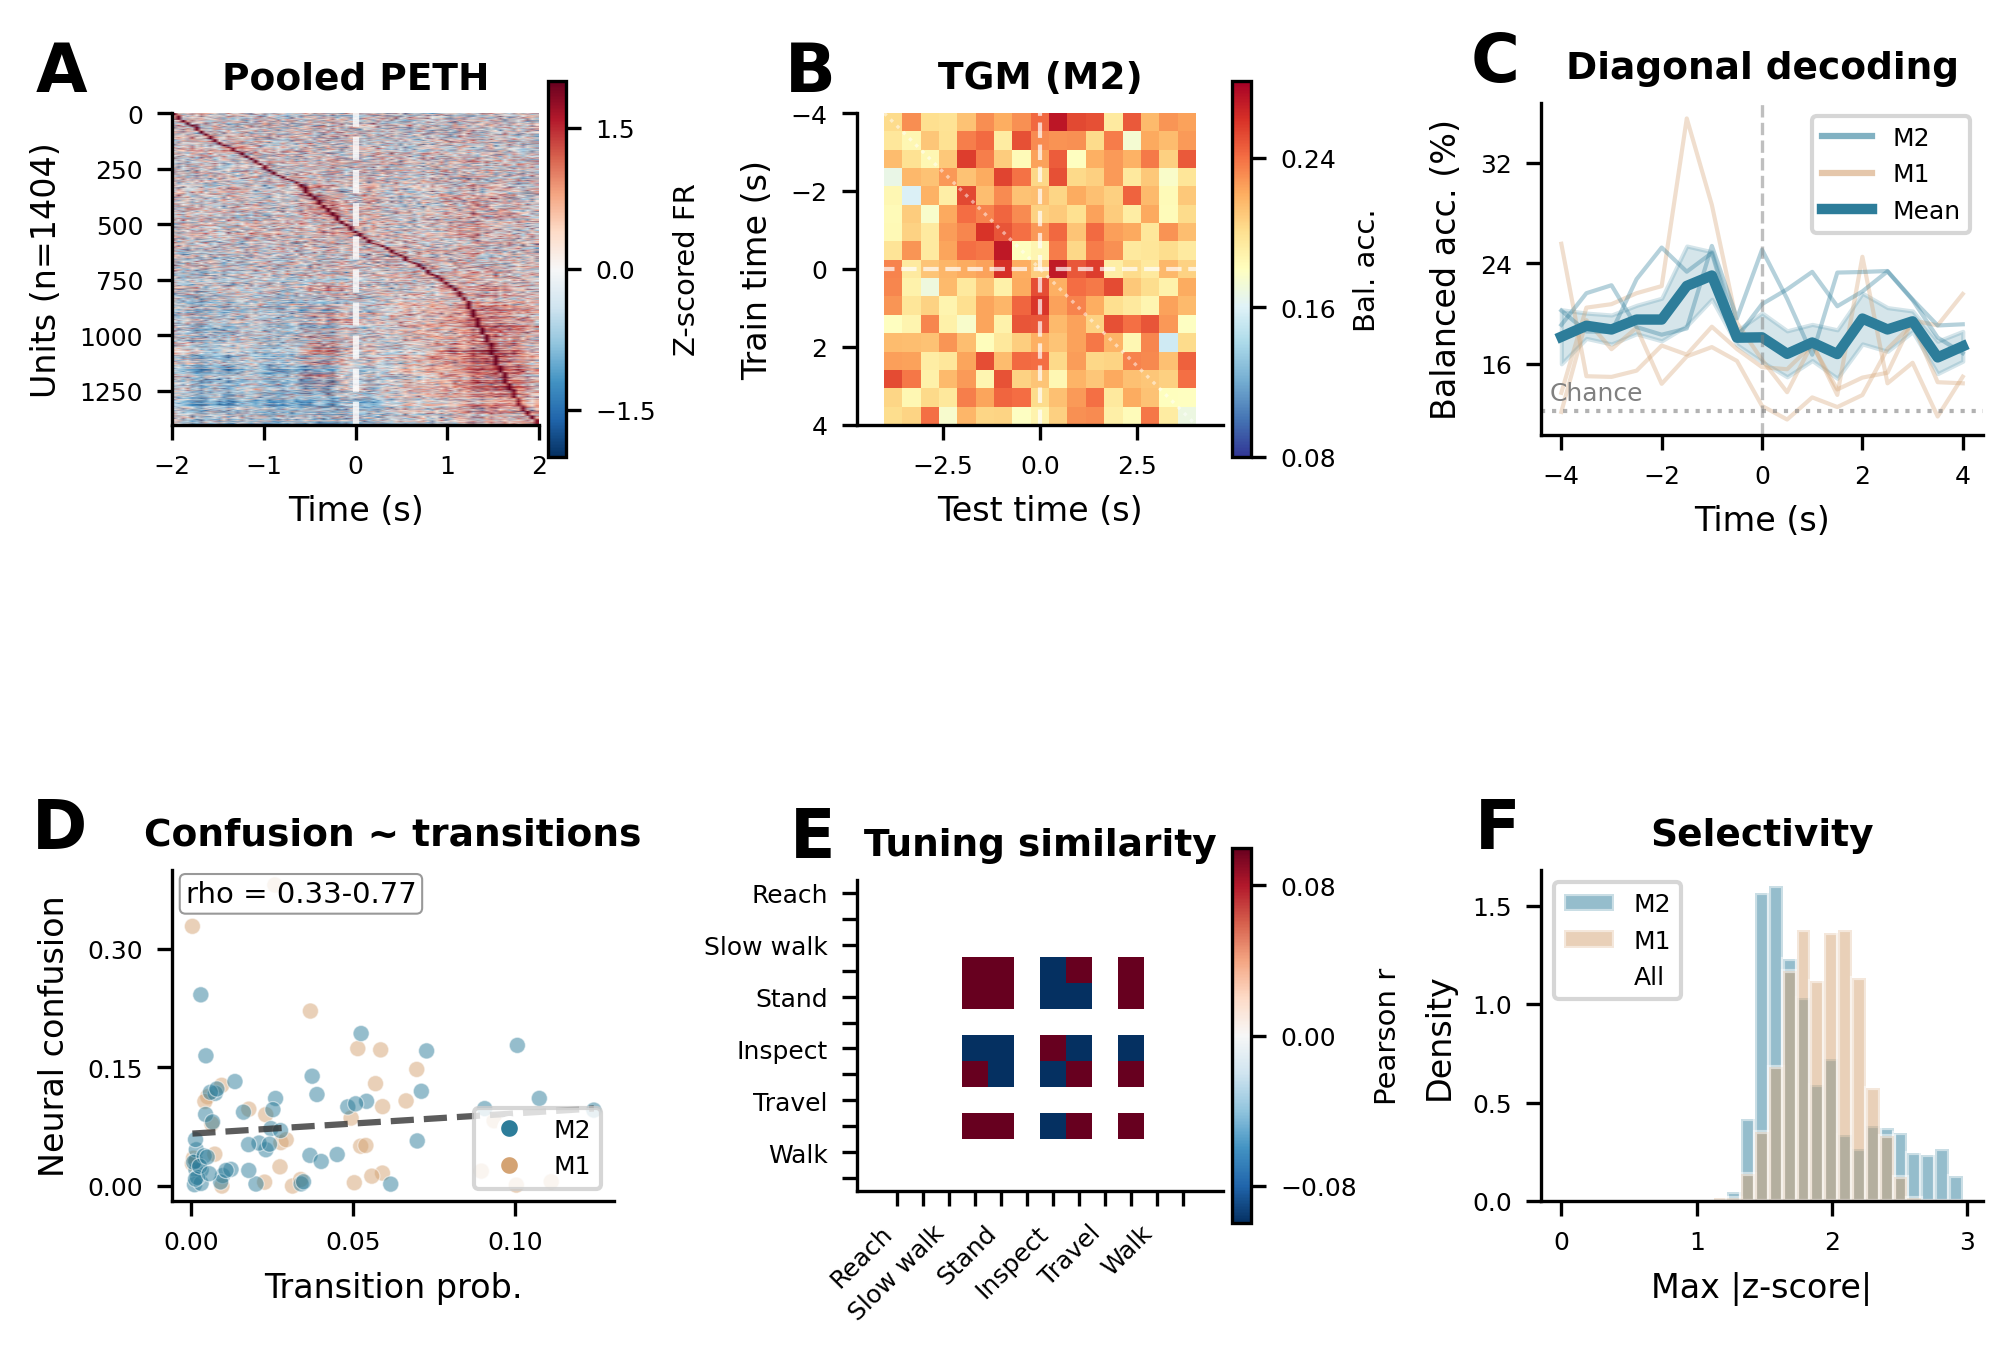

In [6]:
from freemat.single_fm.viz.fig4_composite import fig4_composite
from scipy.stats import pearsonr

# Compute tuning correlation matrix + selectivity from tuning DataFrame
tuning_df = fig4_data["tuning"]
motif_z_cols = sorted([c for c in tuning_df.columns if c.endswith("_z")])
motif_ids = [int(c.replace("motif_", "").replace("_z", "")) for c in motif_z_cols]

tuning_corr = selectivity_arr = selectivity_subjects = None
if len(motif_z_cols) > 0 and len(tuning_df) > 0:
    Z = tuning_df[motif_z_cols].values
    tuning_corr = np.corrcoef(Z.T)
    selectivity_arr = np.nanmax(np.abs(Z), axis=1)
    SMAP = {"M2_0526": "M2", "M2_0605": "M2", "M1_0525": "M1", "M1_0609": "M1", "M1_0613": "M1"}
    selectivity_subjects = tuning_df["session_id"].map(SMAP).values

try:
    fig = fig4_composite(
        peth_data=fig4_data["peth"],
        tgm_data=tgm_data,
        transition_data=fig4_data["transition"],
        confusion_data=fig4_data["confusion"],
        class_labels=fig4_data["class_labels"],
        bank_rsa_results=bank_rsa_results if isinstance(bank_rsa_results, list) else None,
        tuning_corr=tuning_corr,
        tuning_motif_ids=motif_ids,
        selectivity_arr=selectivity_arr,
        selectivity_subjects=selectivity_subjects,
        sessions=list(fig4_data["peth"].keys()),
    )
    plt.show()
except Exception as e:
    print(f"Composite error: {e}")
    import traceback
    traceback.print_exc()